# Software Engineering 458 — Rat Detection Capstone

by Marley Thrift, Audrey Fellows, Ryan Dube and William Ervin

Sequential video classification with OpenCV, PyTorch, a frame encoder, and an LSTM.

**Data layout:** place this notebook in the project root and arrange videos like this:


```text
project/
  train/0/*.mp4
  train/1/*.mp4
  val/0/*.mp4
  val/1/*.mp4
  test/0/*.mp4
  test/1/*.mp4
```

Class folders `0` and `1` are the labels. Keep the data folders on both computers (or configure a shared location); Git does not automatically include local files that are ignored or too large to commit.

## Environment

Use the same Python environment and matching `torch` / `torchvision` versions on both computers. Run in Python 3.14.8. This notebook decodes videos with OpenCV. It uses ImageNet pretrained ResNet18 weights, which torchvision downloads the first time they are requested.

Import/Install

In [5]:
%pip install opencv-python 
%pip install scikit-learn 
%pip install matplotlib
%pip install torch torchvision

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   --- ------------------------------------ 0.8/8.4 MB 2.7 MB/s eta 0:00:03
   ------- -------------------------------- 1.6/8.4 MB 2.8 MB/s eta 0:00:03
   ---------- ----------------------------- 2.1/8.4 MB 2.7 MB/s eta 0:00:03
   ----------- ---------------------------- 2.4/8.4 MB 2.6 MB/s eta 0:00:03
   ------------- -------------------------- 2.9/8.4 MB 2.6 MB/s eta 0:00:03
   ---------------- ----------------------- 3.4/8.4 MB 2.5 MB/s eta 0:00:02
   ------------------ --------------------- 3.9/8.4 MB 2.5 MB/s eta 0:00:02
   --------------------- ------------------ 4.5/8.4 MB 2.5 MB/s eta 0:00:02
   ---------------------- ----------------- 4.7/8.4 MB 2.5 MB/s eta 0:00:02
   ------------------------- -------------- 5.2/8.4 MB 2.5 MB/s eta 0:00:02
   ---------------------


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
from pathlib import Path
import random
from copy import deepcopy

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from IPython.display import clear_output, display
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet18, ResNet18_Weights

#set random seeds for reproducibility
    #seed number does not matter but makes repeated attempts
    #on same machine comparable; 42 has been chosen  
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [7]:
# Directory Paths
PROJECT_ROOT = Path.cwd()
TRAIN_DIR = PROJECT_ROOT / "train"
VAL_DIR = PROJECT_ROOT / "val"
TEST_DIR = PROJECT_ROOT / "test"

print("Project folder:", PROJECT_ROOT)
print("Training folder:", TRAIN_DIR.resolve())
print("Validation folder:", VAL_DIR.resolve())
print("Test folder:", TEST_DIR.resolve())
print("PyTorch:", torch.__version__)

Project folder: f:\Ratt_Gang\Ratt-Gang-Model
Training folder: F:\Ratt_Gang\Ratt-Gang-Model\train
Validation folder: F:\Ratt_Gang\Ratt-Gang-Model\val
Test folder: F:\Ratt_Gang\Ratt-Gang-Model\test
PyTorch: 2.15.0+cpu


Load Data

In [8]:
#collect videos from train/val/test folders

def collect_videos(folder):
    """Return video paths and binary labels from folder/{0,1}/..."""
    folder = Path(folder)
    paths, labels = [], []
    if not folder.is_dir():
        return paths, labels

    for path in sorted(folder.rglob("*")):
        if not path.is_file() or path.suffix.lower() not in {".mp4", ".mov", ".avi", ".mkv"}:
            continue
        relative_parts = path.relative_to(folder).parts
        if not relative_parts or relative_parts[0] not in {"0", "1"}:
            continue
        paths.append(path)
        labels.append(int(relative_parts[0]))
    return paths, labels

train_paths, train_labels = collect_videos(TRAIN_DIR)
val_paths, val_labels = collect_videos(VAL_DIR)
test_paths, test_labels = collect_videos(TEST_DIR)

print(f"Training videos: {len(train_paths)}")
print(f"Validation videos: {len(val_paths)}")
print(f"Test videos: {len(test_paths)}")
for split_name, split_labels in (("train", train_labels), ("val", val_labels), ("test", test_labels)):
    print(f"{split_name} class counts: {{0: {split_labels.count(0)}, 1: {split_labels.count(1)}}}")

if not train_paths:
    raise FileNotFoundError(f"No training videos found under {TRAIN_DIR.resolve()}.")
if not val_paths:
    raise FileNotFoundError(f"No validation videos found under {VAL_DIR.resolve()}.")
if set(val_labels) != {0, 1}:
    raise ValueError("The val/0 and val/1 folders should both contain videos.")
if len(train_paths) != len(train_labels) or len(val_paths) != len(val_labels) or len(test_paths) != len(test_labels):
    raise RuntimeError("A video path is missing a class label; check the 0/1 folder layout.")

Training videos: 164
Validation videos: 34
Test videos: 33
train class counts: {0: 62, 1: 102}
val class counts: {0: 13, 1: 21}
test class counts: {0: 12, 1: 21}


In [9]:
NUM_FRAMES = 16
IMAGE_SIZE = 224
BATCH_SIZE = 4

def find_motion(video_path, min_pixel_change=800, video_pad=2.0, frame_merge_gap=3.0):
    """Return padded (start, end) intervals with detected movement."""
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise RuntimeError(f"OpenCV could not open video: {video_path}")
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    background = cv2.createBackgroundSubtractorMOG2(history=500, varThreshold=25)
    moving_timestamps = []
    frame_number = 0

    while True:
        ok, frame = cap.read()
        if not ok:
            break
        smaller = cv2.resize(frame, None, fx=0.5, fy=0.5)
        mask = background.apply(smaller)
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, None, iterations=2)
        if cv2.countNonZero(mask) > min_pixel_change:
            moving_timestamps.append(frame_number / fps)
        frame_number += 1
    cap.release()

    windows = []
    for timestamp in moving_timestamps:
        if windows and timestamp - windows[-1][1] <= frame_merge_gap:
            windows[-1][1] = timestamp
        else:
            windows.append([timestamp, timestamp])
    return [(max(0, start - video_pad), end + video_pad) for start, end in windows]

# Optional example: find_motion(train_paths[0])


Preproccessing
- turn videos into digestible frames, then tensors for the model to process

In [10]:
class VideoDataset(Dataset):
    """Uniformly sample RGB frames and return [T, C, H, W] plus a binary label."""
    def __init__(self, video_paths, labels, num_frames=NUM_FRAMES, image_size=IMAGE_SIZE):
        if len(video_paths) != len(labels):
            raise ValueError("video_paths and labels must have the same length")
        self.video_paths = [Path(p) for p in video_paths]
        self.labels = [int(label) for label in labels]
        self.num_frames = num_frames
        self.image_size = image_size
        self.mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        self.std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

    def __len__(self):
        return len(self.video_paths)

    def __getitem__(self, index):
        path = self.video_paths[index]
        cap = cv2.VideoCapture(str(path))
        if not cap.isOpened():
            raise RuntimeError(f"OpenCV could not open video: {path}")

        frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if frame_count <= 0:
            cap.release()
            raise RuntimeError(f"Video has no readable frames: {path}")

        frame_indices = np.linspace(0, frame_count - 1, self.num_frames).round().astype(int)
        frames = []
        for frame_index in frame_indices:
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_index))
            ok, frame = cap.read()
            if not ok:
                cap.release()
                raise RuntimeError(f"Could not read frame {frame_index} from {path}")
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frame = cv2.resize(frame, (self.image_size, self.image_size), interpolation=cv2.INTER_AREA)
            tensor = torch.from_numpy(frame.copy()).permute(2, 0, 1).float() / 255.0
            frames.append(tensor)
        cap.release()

        frames = torch.stack(frames)  # [T, C, H, W]
        frames = (frames - self.mean) / self.std
        label = torch.tensor(float(self.labels[index]), dtype=torch.float32)
        return frames, label

In [11]:
train_dataset = VideoDataset(train_paths, train_labels)
val_dataset = VideoDataset(val_paths, val_labels)
test_dataset = VideoDataset(test_paths, test_labels)

# num_workers=0 is reliable in Jupyter on Windows and makes decode errors visible.
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

sample_videos, sample_labels = next(iter(train_loader))
print("Video batch:", tuple(sample_videos.shape))  # [B, T, C, H, W]
print("Label batch:", tuple(sample_labels.shape))  # [B]

Video batch: (4, 16, 3, 224, 224)
Label batch: (4,)


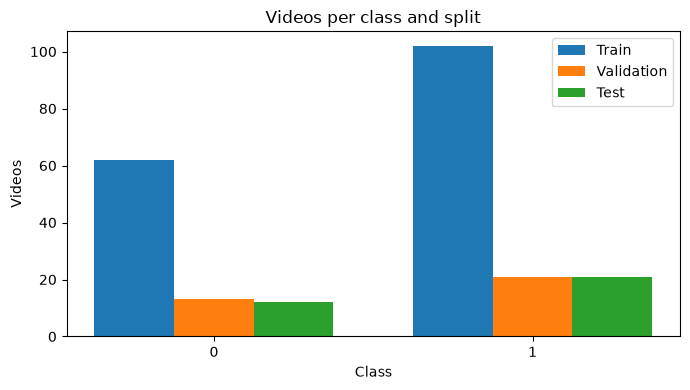

Total Dataset Sizes:
Training set: 164
Validation set: 34
Test set: 33


In [14]:
classes = [0, 1]
train_counts = [sum(label == cls for label in train_labels) for cls in classes]
val_counts = [sum(label == cls for label in val_labels) for cls in classes]
test_counts = [sum(label == cls for label in test_labels) for cls in classes]

x = np.arange(len(classes))
width = 0.25
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(x - width, train_counts, width, label="Train")
ax.bar(x, val_counts, width, label="Validation")
ax.bar(x + width, test_counts, width, label="Test")
ax.set(xticks=x, xticklabels=classes, xlabel="Class", ylabel="Videos", title="Videos per class and split")
ax.legend()
fig.tight_layout()
plt.show()

print("Total Dataset Sizes:")
print(f"Training set: {len(train_paths)}")
print(f"Validation set: {len(val_paths)}")
print(f"Test set: {len(test_paths)}")

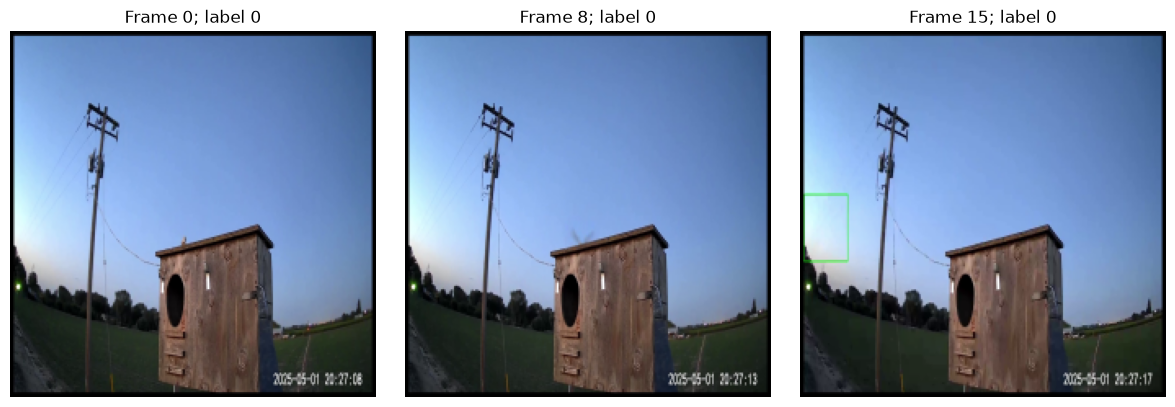

In [15]:
# Preview one sample after undoing ImageNet normalization.
frames, label = train_dataset[0]
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
indices = sorted(set([0, len(frames) // 2, len(frames) - 1]))
fig, axes = plt.subplots(1, len(indices), figsize=(4 * len(indices), 4))
for ax, i in zip(np.atleast_1d(axes), indices):
    frame = (frames[i] * std + mean).clamp(0, 1)
    ax.imshow(frame.permute(1, 2, 0))
    ax.set_title(f"Frame {i}; label {int(label)}")
    ax.axis("off")
fig.tight_layout()
plt.show()

In [16]:
class BinaryVideoClassifier(nn.Module):
    """Encode each frame with pretrained ResNet18, then classify with an LSTM."""
    def __init__(self, hidden_dim=256, dropout=0.3):
        super().__init__()
        backbone = resnet18(weights=ResNet18_Weights.DEFAULT)
        feature_dim = backbone.fc.in_features
        backbone.fc = nn.Identity()
        self.frame_encoder = backbone
        self.temporal_model = nn.LSTM(
            input_size=feature_dim,
            hidden_size=hidden_dim,
            batch_first=True,
        )
        self.classifier = nn.Sequential(
            nn.LayerNorm(hidden_dim),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, videos):
        # videos: [B, T, C, H, W]
        batch_size, num_frames, channels, height, width = videos.shape
        frames = videos.reshape(batch_size * num_frames, channels, height, width)
        features = self.frame_encoder(frames)
        features = features.reshape(batch_size, num_frames, -1)
        sequence, _ = self.temporal_model(features)
        return self.classifier(sequence.mean(dim=1)).squeeze(1)  # [B]

In [17]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
coarse_classifier = BinaryVideoClassifier().to(device)
for parameter in coarse_classifier.frame_encoder.parameters():
    parameter.requires_grad = False

criterion = nn.BCEWithLogitsLoss()
coarse_optimizer = torch.optim.AdamW(
    list(coarse_classifier.temporal_model.parameters())
    + list(coarse_classifier.classifier.parameters()),
    lr=1e-3,  # larger first-stage updates for the new temporal/classification layers
    weight_decay=1e-4,
)
print("Using device:", device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\marle/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


Using device: cpu


In [18]:
def run_epoch(model, loader, criterion, optimizer=None, encoder_eval=False):
    training = optimizer is not None
    model.train(training)
    # Keep pretrained BatchNorm running statistics stable while training selected layers.
    if training and encoder_eval:
        model.frame_encoder.eval()

    total_loss, correct, total = 0.0, 0, 0
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for videos, labels in loader:
            videos = videos.to(device)
            labels = labels.to(device)
            logits = model(videos)
            loss = criterion(logits, labels)

            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()

            predictions = (logits >= 0).long()
            targets = labels.long()
            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            correct += (predictions == targets).sum().item()
            total += batch_size

    return total_loss / total, correct / total


@torch.no_grad()
def evaluate_with_confusion(model, loader, criterion):
    """Return loss, accuracy, and scikit-learn's 2x2 confusion matrix."""
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_targets, all_predictions = [], []

    for videos, labels in loader:
        videos = videos.to(device)
        labels = labels.to(device)
        logits = model(videos)
        loss = criterion(logits, labels)
        targets = labels.long()
        predictions = (logits >= 0).long()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        correct += (predictions == targets).sum().item()
        total += batch_size
        all_targets.extend(targets.cpu().tolist())
        all_predictions.extend(predictions.cpu().tolist())

    matrix = confusion_matrix(all_targets, all_predictions, labels=[0, 1])
    return total_loss / total, correct / total, matrix


def plot_confusion_matrix(matrix, title):
    display = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=[0, 1])
    display.plot(cmap="Blues", values_format="d", colorbar=False)
    display.ax_.set_title(title)
    display.ax_.set_xlabel("Predicted label")
    display.ax_.set_ylabel("True label")
    plt.tight_layout()
    plt.show()


def plot_training_history(history):
    """Refresh loss and accuracy plots after each epoch in a notebook cell."""
    clear_output(wait=True)
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(epochs, history["train_loss"], marker="o", label="Train")
    axes[0].plot(epochs, history["val_loss"], marker="o", label="Validation")
    axes[0].set(title="Loss by epoch", xlabel="Epoch", ylabel="BCE loss")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(epochs, history["train_accuracy"], marker="o", label="Train")
    axes[1].plot(epochs, history["val_accuracy"], marker="o", label="Validation")
    axes[1].set(title="Accuracy by epoch", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1))
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    fig.tight_layout()
    display(fig)
    plt.close(fig)

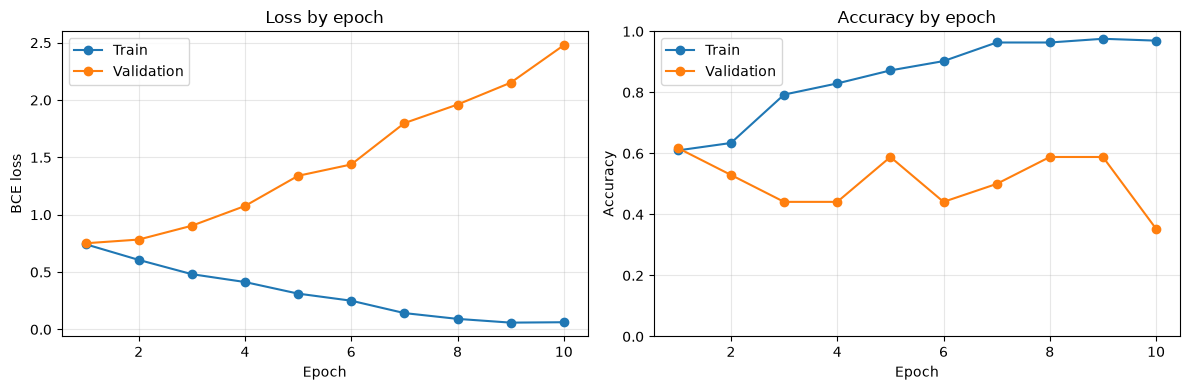

Fine-tuned classifier | epoch 5 | train loss 0.0627, accuracy 0.970 | val loss 2.4784, accuracy 0.353
Restored best model from Coarse classifier, epoch 1 (val loss 0.7512).


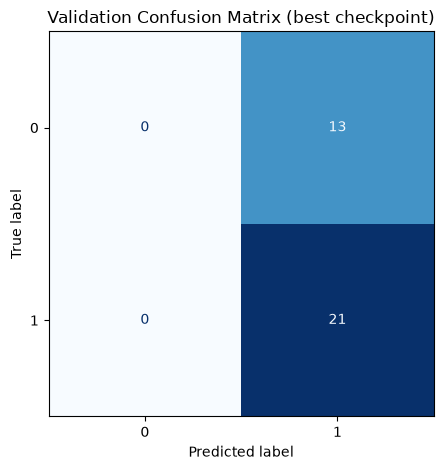

Test loss 0.7185 | test accuracy 0.636


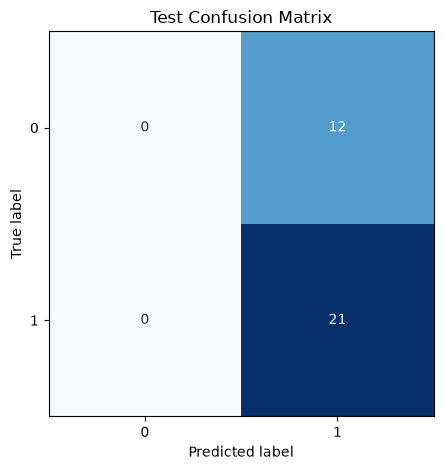

In [19]:
COARSE_EPOCHS = 5
FINETUNE_EPOCHS = 5
FINETUNE_BACKBONE_LR = 1e-5
FINETUNE_HEAD_LR = 1e-4

history = {
    "train_loss": [], "val_loss": [],
    "train_accuracy": [], "val_accuracy": [],
}
best_val_loss = float("inf")
best_stage = None
best_epoch = None
best_weights = None
best_val_confusion = None

def record_epoch(model, optimizer, epoch_number, stage_name, encoder_eval):
    global best_val_loss, best_stage, best_epoch, best_weights, best_val_confusion
    train_loss, train_accuracy = run_epoch(
        model, train_loader, criterion, optimizer, encoder_eval=encoder_eval
    )
    val_loss, val_accuracy, val_matrix = evaluate_with_confusion(
        model, val_loader, criterion
    )
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_stage = stage_name
        best_epoch = epoch_number
        best_weights = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}
        best_val_confusion = val_matrix.copy()

    plot_training_history(history)
    print(
        f"{stage_name} | epoch {epoch_number} | "
        f"train loss {train_loss:.4f}, accuracy {train_accuracy:.3f} | "
        f"val loss {val_loss:.4f}, accuracy {val_accuracy:.3f}"
    )


# Stage 1: classifier 1 learns the temporal and binary head at a higher learning rate.
for epoch in range(1, COARSE_EPOCHS + 1):
    record_epoch(
        coarse_classifier, coarse_optimizer, epoch,
        "Coarse classifier", encoder_eval=True
    )

# Stage 2: classifier 2 starts from classifier 1 and fine-tunes ResNet's last block
# plus the temporal/head layers with lower learning rates.
fine_classifier = deepcopy(coarse_classifier).to(device)
for parameter in fine_classifier.frame_encoder.parameters():
    parameter.requires_grad = False
for parameter in fine_classifier.frame_encoder.layer4.parameters():
    parameter.requires_grad = True

fine_optimizer = torch.optim.AdamW(
    [
        {"params": fine_classifier.frame_encoder.layer4.parameters(), "lr": FINETUNE_BACKBONE_LR},
        {"params": fine_classifier.temporal_model.parameters(), "lr": FINETUNE_HEAD_LR},
        {"params": fine_classifier.classifier.parameters(), "lr": FINETUNE_HEAD_LR},
    ],
    weight_decay=1e-4,
)
for epoch in range(1, FINETUNE_EPOCHS + 1):
    record_epoch(
        fine_classifier, fine_optimizer, epoch,
        "Fine-tuned classifier", encoder_eval=True
    )

if best_weights is None:
    raise RuntimeError("Training did not produce a validation checkpoint.")
model = fine_classifier if best_stage == "Fine-tuned classifier" else coarse_classifier
model.load_state_dict(best_weights)
print(f"Restored best model from {best_stage}, epoch {best_epoch} (val loss {best_val_loss:.4f}).")
plot_confusion_matrix(best_val_confusion, "Validation Confusion Matrix (best checkpoint)")

# Evaluate the held-out test set once, after selecting the model with validation loss.
if len(test_dataset):
    test_loss, test_accuracy, test_matrix = evaluate_with_confusion(model, test_loader, criterion)
    print(f"Test loss {test_loss:.4f} | test accuracy {test_accuracy:.3f}")
    plot_confusion_matrix(test_matrix, "Test Confusion Matrix")
else:
    print("No test videos found; skipping final test evaluation.")

In [ ]:
model_path = PROJECT_ROOT / "binary_video_classifier.pt"
torch.save(model.state_dict(), model_path)
print("Saved model to:", model_path)